# Análisis de hábitos de compra en Instacart

## Introducción

Instacart es una plataforma de comercio electrónico especializada en la compra y entrega de productos de supermercado. A través de ella, los usuarios pueden realizar pedidos en línea y recibir sus compras a domicilio.

En este proyecto se realiza un análisis exploratorio de datos para identificar patrones de comportamiento en las compras de los usuarios, utilizando información histórica sobre pedidos, productos y hábitos de recompra.

El análisis se enfoca en explorar la frecuencia y distribución de los pedidos, los horarios y días de mayor actividad, los productos más populares, los artículos que se compran con mayor frecuencia y los patrones de recompra de los clientes.

Para desarrollar este análisis se utilizan Python, Pandas y Matplotlib, aplicando técnicas de limpieza, transformación, agrupación y visualización de datos.

**Objetivo:** comprender los hábitos de compra de los usuarios de Instacart mediante el análisis de sus pedidos e identificar patrones relevantes en el comportamiento de consumo.

In [1]:
# Importar librerías principales para manipulación de datos y visualización

import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Cargar los datasets desde la carpeta Datasets del proyecto

df_orders = pd.read_csv('Datasets/instacart_orders.csv', sep=';')
df_products = pd.read_csv('Datasets/products.csv', sep=';')
df_aisles = pd.read_csv('Datasets/aisles.csv', sep=';')
df_departments = pd.read_csv('Datasets/departments.csv', sep=';')
df_order_products = pd.read_csv('Datasets/order_products.csv', sep=';')

Al revisar la columna department_id en los productos sin nombre, el único valor que aparece es el 21. Esto confirma que el 100% de estos productos pertenecen a dicho departamento.

In [3]:
# Inspeccionar estructura, tipos de datos y primeras filas de la tabla de pedidos

print("=== ORDERS ===")
df_orders.info(show_counts=True)
display(df_orders.head())

=== ORDERS ===
<class 'pandas.DataFrame'>
RangeIndex: 478967 entries, 0 to 478966
Data columns (total 6 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   order_id                478967 non-null  int64  
 1   user_id                 478967 non-null  int64  
 2   order_number            478967 non-null  int64  
 3   order_dow               478967 non-null  int64  
 4   order_hour_of_day       478967 non-null  int64  
 5   days_since_prior_order  450148 non-null  float64
dtypes: float64(1), int64(5)
memory usage: 21.9 MB


,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,1515936,183418,11,6,13,30.0
1,1690866,163593,5,5,12,9.0
2,1454967,39980,4,5,19,2.0
3,1768857,82516,56,0,20,10.0
4,3007858,196724,2,4,12,17.0


In [4]:
# Inspeccionar estructura y primeras filas de la tabla de productos

print("=== PRODUCTS ===")
df_products.info(show_counts=True)
display(df_products.head())

=== PRODUCTS ===
<class 'pandas.DataFrame'>
RangeIndex: 49694 entries, 0 to 49693
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   product_id     49694 non-null  int64
 1   product_name   48436 non-null  str  
 2   aisle_id       49694 non-null  int64
 3   department_id  49694 non-null  int64
dtypes: int64(3), str(1)
memory usage: 1.5 MB


,product_id,product_name,aisle_id,department_id
0,1,Chocolate Sandwich Cookies,61,19
1,2,All-Seasons Salt,104,13
2,3,Robust Golden Unsweetened Oolong Tea,94,7
3,4,Smart Ones Classic Favorites Mini Rigatoni Wit...,38,1
4,5,Green Chile Anytime Sauce,5,13


In [5]:
# Inspeccionar estructura y primeras filas de la tabla de pasillos

print("=== AISLES ===")
df_aisles.info(show_counts=True)
display(df_aisles.head())

=== AISLES ===
<class 'pandas.DataFrame'>
RangeIndex: 134 entries, 0 to 133
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   aisle_id  134 non-null    int64
 1   aisle     134 non-null    str  
dtypes: int64(1), str(1)
memory usage: 2.2 KB


,aisle_id,aisle
0,1,prepared soups salads
1,2,specialty cheeses
2,3,energy granola bars
3,4,instant foods
4,5,marinades meat preparation


In [6]:
# Inspeccionar estructura y primeras filas de la tabla de departamentos

print("=== DEPARTMENTS ===")
df_departments.info(show_counts=True)
display(df_departments.head())

=== DEPARTMENTS ===
<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   department_id  21 non-null     int64
 1   department     21 non-null     str  
dtypes: int64(1), str(1)
memory usage: 468.0 bytes


,department_id,department
0,1,frozen
1,2,other
2,3,bakery
3,4,produce
4,5,alcohol


In [7]:
# Inspeccionar estructura y primeras filas de los productos por pedido

print("=== ORDER PRODUCTS ===")
df_order_products.info(show_counts=True)
display(df_order_products.head())

=== ORDER PRODUCTS ===
<class 'pandas.DataFrame'>
RangeIndex: 4545007 entries, 0 to 4545006
Data columns (total 4 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   order_id           4545007 non-null  int64  
 1   product_id         4545007 non-null  int64  
 2   add_to_cart_order  4544171 non-null  float64
 3   reordered          4545007 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 138.7 MB


,order_id,product_id,add_to_cart_order,reordered
0,2141543,11440,17.0,0
1,567889,1560,1.0,1
2,2261212,26683,1.0,1
3,491251,8670,35.0,1
4,2571142,1940,5.0,1


Después de cargar los 5 archivos y darles un primer vistazo con .info() y .head(), esto fue lo que se encontró:

Lectura de los archivos:
Todos los archivos venían separados por punto y coma (;), así que se usó sep=';' en read_csv porque si no, Pandas juntaba todo en una sola columna.

Valores que faltan (nulos):

En la tabla de pedidos (orders), a la columna days_since_prior_order le faltan datos. Pero tiene sentido: son los primeros pedidos de los clientes (order_number = 1), así que no hay un "pedido anterior" con el cual comparar.

En la tabla de productos (products), hay varios product_name vacíos. Como no sabemos cómo se llaman, habrá que ponerles 'Missing' o 'Unknown' para no borrar las filas.

En order_products, faltan algunos valores en add_to_cart_order, sobre todo en carritos que tienen muchísimos productos.

Tipos de datos por corregir:

La columna add_to_cart_order en order_products se cargó como decimal (float64) únicamente porque contiene valores nulos. Una vez tratados los datos faltantes, evaluaremos convertirla a entero (int64).

En resumen para el Paso 2: Buscar si hay filas repetidas (duplicadas) para borrarlas, rellenar los datos nulos de forma lógica y cambiar los tipos de datos para que todo quede limpio antes de hacer los gráficos.

# Paso 2. Preprocesamiento de los datos

Preprocesar los datos:

- Verificar y corregir los tipos de datos (por ejemplo, asegúrate de que las columnas de ID sean números enteros).
- Identificar y completar los valores ausentes.
- Identificar y eliminar los valores duplicados.
- Limpiar duplicados
- Manejar los datos nulos
- Corregir tipos de datos

## Encuontrar y eliminar los valores duplicados

### `orders` data frame

In [8]:
# Filtrar y mostrar las filas que están totalmente duplicadas en la tabla de pedidos

df_orders[df_orders.duplicated()]

,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
145574,794638,50898,24,3,2,2.0
223105,2160484,107525,16,3,2,30.0
230807,1918001,188546,14,3,2,16.0
266232,1782114,106752,1,3,2,NaN
273805,1112182,202304,84,3,2,6.0
284038,2845099,31189,11,3,2,7.0
311713,1021560,53767,3,3,2,9.0
321100,408114,68324,4,3,2,18.0
323900,1919531,191501,32,3,2,7.0
345917,2232988,82565,1,3,2,NaN


Existen filas completamente duplicadas en la tabla df_orders. Al analizarlas tienen en común que comparten exactamente los mismos valores en todas sus columnas: el mismo order_id, user_id, order_number, order_dow (día de la semana 3, correspondiente al miércoles) y order_hour_of_day (2:00 a.m.).

In [9]:
# Filtrar todos los pedidos realizados los miércoles (día 3) a las 2:00 a.m. para investigar el patrón de los duplicados

pedidos_miercoles_2am = df_orders[(df_orders['order_dow'] == 3) & (df_orders['order_hour_of_day'] == 2)]
display(pedidos_miercoles_2am)

,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
4838,2766110,162084,41,3,2,16.0
5156,2190225,138285,18,3,2,11.0
15506,553049,58599,13,3,2,7.0
18420,382357,120200,19,3,2,11.0
24691,690242,77357,2,3,2,9.0
...,...,...,...,...,...,...
457013,3384021,14881,6,3,2,30.0
458816,910166,164782,18,3,2,4.0
459635,1680532,106435,6,3,2,21.0
468324,222962,54979,59,3,2,3.0


Se observa una concentración de registros duplicados correspondientes a pedidos realizados los miércoles a las 2:00 a. m. Este patrón podría estar relacionado con alguna anomalía en el registro o la exportación de los datos. Sin embargo, con la información disponible no es posible determinar la causa exacta.

In [10]:
# Eliminar las filas totalmente duplicadas del DataFrame de pedidos y reiniciar los índices

df_orders = df_orders.drop_duplicates().reset_index(drop=True)

In [11]:
# Confirmar que ya no quedan filas totalmente duplicadas tras la limpieza
print("Filas duplicadas tras la limpieza:", df_orders.duplicated().sum())

Filas duplicadas tras la limpieza: 0


In [12]:
# Verificar que no existan identificadores de pedido (order_id) repetidos en la tabla

print("IDs de pedido duplicados tras la limpieza:", df_orders['order_id'].duplicated().sum())

IDs de pedido duplicados tras la limpieza: 0


Al revisar la tabla de pedidos (df_orders), se encontró un grupo de filas totalmente duplicadas. Todas coincidían exactamente en los mismos datos y se registraron el mismo día y a la misma hora (miércoles a las 2:00 a.m.), lo cual apunta a un fallo momentáneo del sistema o a un error al exportar los datos.

Se usó .drop_duplicates() para borrar las filas repetidas y se dejó solo una copia de cada pedido. Después se volvió a verificar con .duplicated().sum() tanto en la tabla completa como en la columna order_id para confirmar que ya no quedara ningún duplicado. Ambos conteos dieron 0, así que los pedidos ya quedaron limpios.

### `products` data frame

In [13]:
# Verificar si existen filas idénticas completas en la tabla de productos

print("Filas totalmente duplicadas:", df_products.duplicated().sum())

Filas totalmente duplicadas: 0


In [14]:
# Comprobar que no existan IDs de producto repetidos

print("IDs de producto duplicados:", df_products['product_id'].duplicated().sum())

IDs de producto duplicados: 0


In [15]:
# Convertir nombres a mayúsculas para buscar duplicados de texto ignorando diferencias de formato

nombres_mayusculas = df_products['product_name'].str.upper()
print("Nombres duplicados (en mayúsculas):", nombres_mayusculas.duplicated().sum())

Nombres duplicados (en mayúsculas): 1361


In [16]:
# Descartar nulos temporalmente para calcular los nombres duplicados reales de productos

nombres_sin_nulos = df_products['product_name'].dropna().str.upper()
print("Nombres duplicados sin contar nulos:", nombres_sin_nulos.duplicated().sum())

Nombres duplicados sin contar nulos: 104


Al revisar la tabla de productos no se encontraron filas repetidas completas ni IDs de producto duplicados; cada producto tiene su propio ID único. Sin embargo, al poner los nombres en mayúsculas para comparar mejor, se encontraron nombres de productos que sí se repiten.

Se identificaron cuántos nombres repetidos existen (tanto contando los valores nulos como sin ellos). Como los product_id son únicos, no se eliminó nada aún para no perder el historial de ventas, pero estos duplicados en los nombres se tendrán en cuenta para normalizarlos o manejarlos más adelante.

### `departments` data frame

In [17]:
# Verificar si existen filas totalmente idénticas en la tabla de departamentos

print("Filas totalmente duplicadas:", df_departments.duplicated().sum())

Filas totalmente duplicadas: 0


In [18]:
# Comprobar que cada departamento tenga un identificador único (department_id)

print("IDs de departamento duplicados:", df_departments['department_id'].duplicated().sum())

IDs de departamento duplicados: 0


La tabla de departamentos está impecable. No hay filas repetidas y cada departamento tiene un department_id único, sin ningún duplicado.
No hizo falta eliminar ni modificar ninguna fila. La información está lista para usarse tal cual.

### `aisles` data frame

In [19]:
# Verificar si existen filas idénticas completas en la tabla de pasillos

print("Filas totalmente duplicadas:", df_aisles.duplicated().sum())

Filas totalmente duplicadas: 0


In [20]:
# Comprobar que no existan identificadores de pasillo (aisle_id) repetidos

print("IDs de pasillo duplicados:", df_aisles['aisle_id'].duplicated().sum())

IDs de pasillo duplicados: 0


La tabla de pasillos (df_aisles) no tiene ninguna fila duplicada ni tampoco hay IDs de pasillo repetidos. Cada pasillo tiene su identificador único y bien registrado.
No hizo falta aplicar ninguna limpieza ni eliminar datos, ya que la tabla viene completamente limpia desde el origen.

### `order_products` data frame

In [21]:
# Verificar si existen filas completamente idénticas en los registros de productos por pedido

print("Filas totalmente duplicadas:", df_order_products.duplicated().sum())

Filas totalmente duplicadas: 0


In [22]:
# Verificar que un mismo producto no esté registrado dos veces dentro de un mismo pedido (orden)

print("Duplicados de combinación order_id + product_id:", df_order_products.duplicated(subset=['order_id', 'product_id']).sum())

Duplicados de combinación order_id + product_id: 0


Al revisar la tabla df_order_products no se encontraron filas totalmente duplicadas. Tampoco hay "duplicados engañosos" (es decir, combinaciones donde el mismo producto aparezca repetido dentro de un mismo pedido).
No fue necesario aplicar ningún filtro de eliminación. La información mantiene su integridad y está lista para el análisis.

## Encuentra y elimina los valores ausentes

Al trabajar con valores duplicados, pudimos observar que también nos falta investigar valores ausentes:

* La columna `'product_name'` de la tabla products.
* La columna `'days_since_prior_order'` de la tabla orders.
* La columna `'add_to_cart_order'` de la tabla order_productos.

### `products` data frame

In [23]:
# Filtrar y guardar en un DataFrame los productos que no tienen nombre (valores nulos NaN)

productos_sin_nombre = df_products[df_products['product_name'].isna()]
productos_sin_nombre

,product_id,product_name,aisle_id,department_id
37,38,NaN,100,21
71,72,NaN,100,21
109,110,NaN,100,21
296,297,NaN,100,21
416,417,NaN,100,21
...,...,...,...,...
49552,49553,NaN,100,21
49574,49575,NaN,100,21
49640,49641,NaN,100,21
49663,49664,NaN,100,21


Existen productos que no tienen registrado su nombre. Sin embargo, todos conservan su product_id, su aisle_id y su department_id, por lo que el registro existe pero falta la etiqueta de texto.

In [24]:
# Obtener los pasillos únicos asociados a los productos sin nombre

print("Pasillos de productos sin nombre:", productos_sin_nombre['aisle_id'].unique())

Pasillos de productos sin nombre: [100]


Al revisar la columna aisle_id únicamente para los productos con nombre faltante, el único valor que aparece es el 100. Esto confirma que el 100% de los productos sin nombre pertenecen al pasillo 100 (que corresponde a productos no clasificados o sin categoría definida).

In [25]:
# Obtener los departamentos únicos asociados a los productos sin nombre

print("Departamentos de productos sin nombre:", productos_sin_nombre['department_id'].unique())

Departamentos de productos sin nombre: [21]


Al revisar la columna department_id en los productos sin nombre, el único valor que aparece es el 21. Esto confirma que el 100% de estos productos pertenecen a dicho departamento.

In [26]:
# Consultar el nombre oficial del pasillo 100 y del departamento 21

display(df_aisles[df_aisles['aisle_id'] == 100])
display(df_departments[df_departments['department_id'] ==21])

,aisle_id,aisle
99,100,missing


,department_id,department
20,21,missing


Tanto el pasillo 100 como el departamento 21 corresponden a la categoría 'missing' (faltantes). Esto confirma que los productos sin nombre fueron asignados a una categoría genérica dentro del sistema.

In [27]:
#Voy a rellenar valores nulos en product_name con 'Unknown'
df_products['product_name'] = df_products['product_name'].fillna('Unknown')
#Confirmar que ya no existen nulos
print("Valores ausentes restantes en product_name:", df_products['product_name'].isna().sum())

Valores ausentes restantes en product_name: 0


Se imputaron todos los valores ausentes en la columna product_name reemplazándolos con la etiqueta 'Unknown'. Esto permite mantener las filas intactas sin perder el historial de ventas ni romper las asociaciones con los product_id. Al volver a verificar, los valores ausentes se redujeron a 0.

### `orders` data frame

In [28]:
# Encuentra los valores ausentes
#Contar el total de valores nulos NaN en cada columna de la tabla df_orders
df_orders.isna().sum()

order_id                      0
user_id                       0
order_number                  0
order_dow                     0
order_hour_of_day             0
days_since_prior_order    28817
dtype: int64

In [29]:
#Verificar si existen datos ausentes en days_since_prior_order para pedidos que NO son el primero del cliente
df_orders[df_orders['days_since_prior_order'].isna() & (df_orders['order_number'] != 1)]

,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order


Los únicos valores vacíos están en la columna days_since_prior_order y todos corresponden al primer pedido de cada cliente (order_number == 1) lo cual tiene total sentido porque no hay compras previas con qué comparar. Se dejaron estos nulos tal cual para no alterar ni inventar promedios al hacer cálculos después.

### `order_products` data frame

In [30]:
#Contar el total de valores nulos NaN en cada columna de df_order_products
df_order_products.isna().sum()

order_id               0
product_id             0
add_to_cart_order    836
reordered              0
dtype: int64

In [31]:
#Revisar los valores mínimos y máximos de add_to_cart_order
print("Mínimo:", df_order_products['add_to_cart_order'].min())
print("Máximo:", df_order_products['add_to_cart_order'].max())

Mínimo: 1.0
Máximo: 64.0


Hay 836 valores vacíos únicamente en la columna add_to_cart_order, mientras que las demás están completas. En cuanto a la secuencia del carrito, los valores van desde el 1 hasta el 64 indicando que los productos se registraron en el orden correcto y sin números raros o negativos.

In [32]:

#Filtrar los registros con valores ausentes en 'add_to_cart_order' y guardar sus order_id únicos
pedidos_con_nulos = df_order_products[df_order_products['add_to_cart_order'].isna()]['order_id'].unique()

In [33]:
#Filtrar el DataFrame con los pedidos que tienen nulos, agrupar por order_id y contar los productos por pedido
conteos_pedidos_nulos = df_order_products[df_order_products['order_id'].isin(pedidos_con_nulos)].groupby('order_id')['product_id'].count()

#Revisar el valor mínimo del conteo de productos
print('Mínimo número de productos en estos pedidos:', conteos_pedidos_nulos.min())

Mínimo número de productos en estos pedidos: 65


Al revisar los pedidos que contienen valores ausentes en add_to_cart_order, noté que todos tienen más de 64 productos agregados al carrito (el valor mínimo del conteo es 65). Esto indica que el sistema dejó de registrar la secuencia cuando los pedidos eran muy grandes.

In [34]:

#Reemplazar los valores nulos en 'add_to_cart_order' con 999 y convertir la columna a entero
df_order_products['add_to_cart_order'] = df_order_products['add_to_cart_order'].fillna(999).astype(int)

#confirmar que ya no quedan valores ausentes
print("Valores ausentes restantes:", df_order_products['add_to_cart_order'].isna().sum())

Valores ausentes restantes: 0


En esta etapa se dejó la información lista para trabajar. No se encontraron filas duplicadas ni IDs repetidos en las tablas principales. En la tabla products se rellenaron los nombres faltantes con la etiqueta 'Unknown', identificando que pertenecían al pasillo 100 del departamento 21 (categoría "missing"). En orders, los valores nulos correspondían lógicamente a los primeros pedidos de los usuarios. Finalmente, en order_products se identificó que los valores faltantes en add_to_cart_order ocurrían únicamente en pedidos con más de 64 artículos, por lo que se asignó el valor 999 para convertir la columna a enteros sin perder registros.

# Paso 3. Análisis de los datos


In [35]:
#Verificar valores mínimos y máximos para las horas del día (deben ir de 0 a 23)
print("Hora mínima:", df_orders['order_hour_of_day'].min())
print("Hora máxima:", df_orders['order_hour_of_day'].max())

Hora mínima: 0
Hora máxima: 23


In [36]:
#Verificar valores mínimos y máximos para los días de la semana (deben ir de 0 a 6)
print("Día mínimo", df_orders['order_dow'].min())
print("Día máximo", df_orders['order_dow'].max())

Día mínimo 0
Día máximo 6


Los valores de ambas columnas son correctos. Las horas van del 0 al 23 (por las 24 horas del día) y los días de la semana del 0 al 6 (osea 7 días de la semana). No hay datos fuera de rango ni números extraños

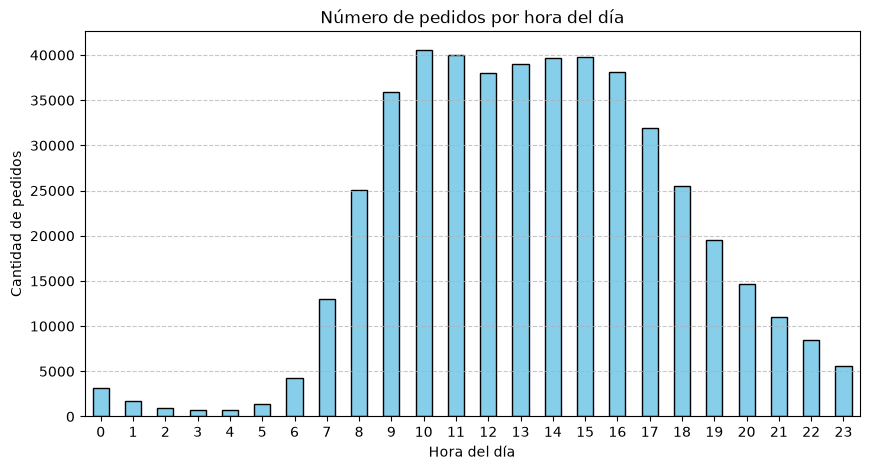

In [37]:
#Agrupar por hora del día y contar el número de pedidos
pedidos_por_hora = df_orders['order_hour_of_day'].value_counts().sort_index()

#Graficar
plt.figure(figsize=(10, 5))
pedidos_por_hora.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Número de pedidos por hora del día')
plt.xlabel('Hora del día')
plt.ylabel('Cantidad de pedidos')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

La mayoría de los pedidos se concentran a los largo del día entre las 9:00 y las 16:00 horas, teniendo su punto más alto a las 10:00 horas. En contraste durante la madrugada (aproximadamente de 0:00 a 6:00 horas) la cantidad de compras baja de forma considerable.

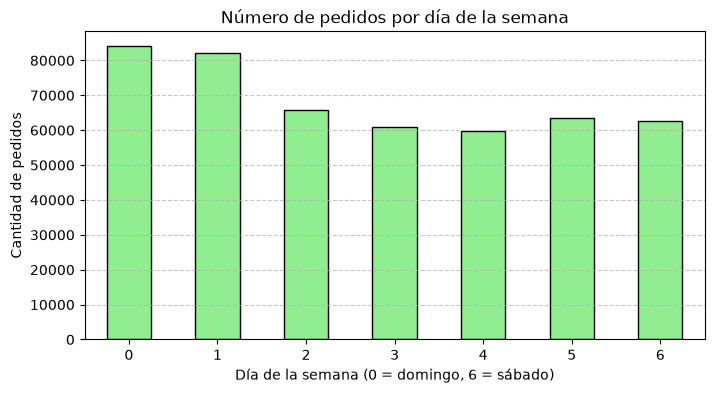

In [38]:
#Agrupar por día de la semana y contar pedidos
pedidos_por_día = df_orders['order_dow'].value_counts().sort_index()

#Graficar
plt.figure(figsize=(8, 4))
pedidos_por_día.plot(kind='bar', color='lightgreen', edgecolor='black')
plt.title('Número de pedidos por día de la semana')
plt.xlabel('Día de la semana (0 = domingo, 6 = sábado)')
plt.ylabel('Cantidad de pedidos')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

Los días 0 y 6 son por mucho los que acumulan más compras en la semana. A partir del día 2 la actividad baja y se mantiene bastante estable durante el resto de los días laborales.

Tiempo mínimo de espera: 0.0
Tiempo máximo de espera: 30.0


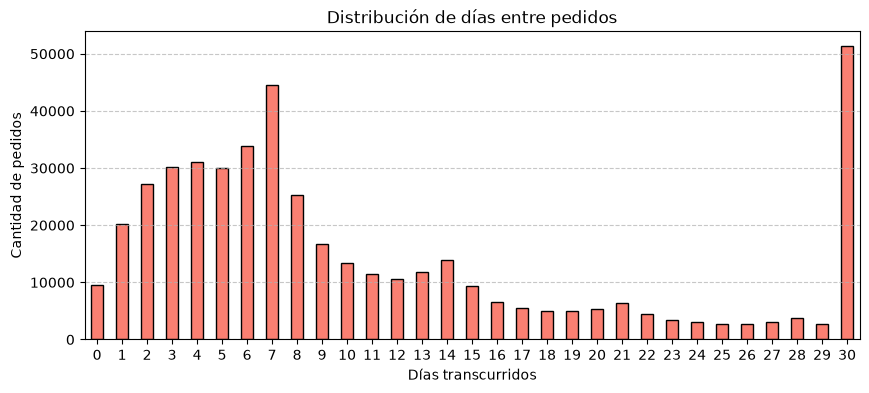

In [39]:
#Exluir NaNs para trabajar solo con tiempos de espera validos
dias_validos = df_orders['days_since_prior_order'].dropna()

#Contar la frecuencia de días transcurridos entre pedidos
dias_espera = dias_validos.value_counts().sort_index()
dias_espera.index = dias_espera.index.astype(int)

#Imprimir min y max
print("Tiempo mínimo de espera:", dias_validos.min())
print("Tiempo máximo de espera:", dias_validos.max())

#Graficar
plt.figure(figsize=(10, 4))
dias_espera.plot(kind='bar', color='salmon', edgecolor='black')
plt.title('Distribución de días entre pedidos')
plt.xlabel('Días transcurridos')
plt.ylabel('Cantidad de pedidos')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

El rango va desde un mínimo de 0 días (compras realizadas el mismo día) hasta un máximo de 30 días. Destacan picos muy marcados a los 7 y 30 días, lo que sugiere que algunos usuarios siguen rutinas de compra semanales o mensuales. El valor máximo de 30 días podría representar una categoría agrupada para intervalos de 30 días o más, por lo que conviene considerar esta característica al interpretar la distribución.

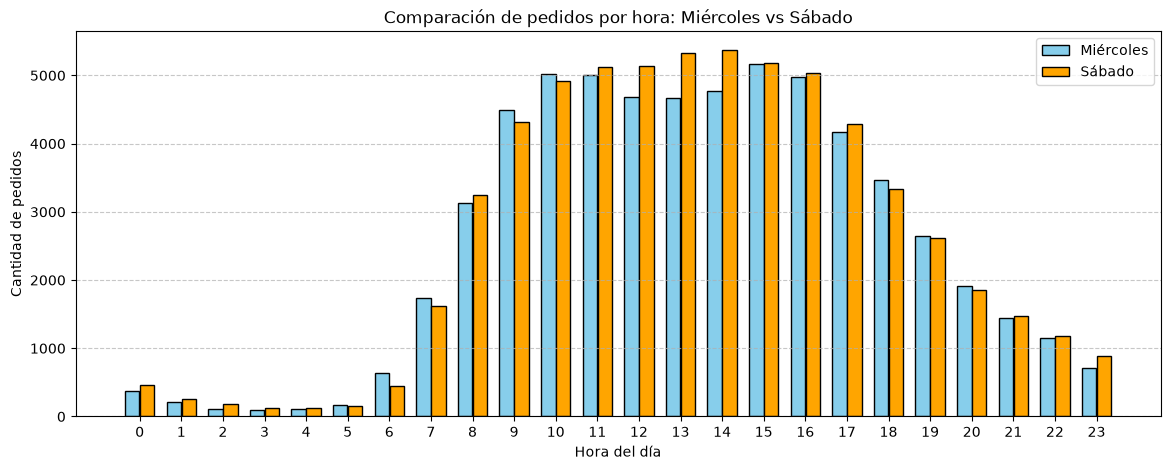

In [40]:
#Filtrar los pedidos para miércoles (3) y sábados (6)
miercoles = df_orders[df_orders['order_dow'] == 3]['order_hour_of_day'].value_counts().sort_index()
sabados = df_orders[df_orders['order_dow'] == 6]['order_hour_of_day'].value_counts().sort_index()

miercoles = miercoles.reindex(range(24), fill_value=0)
sabados = sabados.reindex(range(24), fill_value=0)

plt.figure(figsize=(14, 5))
plt.bar(miercoles.index - 0.18, miercoles.values, width=0.35, label='Miércoles', color='skyblue', edgecolor='black')
plt.bar(sabados.index + 0.18, sabados.values, width=0.35, label='Sábado', color='orange', edgecolor='black')

plt.title('Comparación de pedidos por hora: Miércoles vs Sábado')
plt.xlabel('Hora del día')
plt.ylabel('Cantidad de pedidos')
plt.xticks(range(0, 24))
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

En general los dos días se comportan muy parecido: la gente empieza a comprar más en la mañana, el pico fuerte llega a mediodía y ya en la noche vuelve a bajar. El sábado supera al miércoles principalmente en las horas centrales del día, y el miércoles mueve ligeramente más volumen en la noche.

In [41]:
#Contar cuántos pedidos hizo cada usuario
pedidos_por_cliente = df_orders.groupby('user_id')['order_number'].max()
distribucion_pedidos = pedidos_por_cliente.value_counts().sort_index()

#Mostrar los primeros registros para revisar
print(distribucion_pedidos.head())

order_number
1     7840
2     9113
3    10510
4    12368
5    10406
Name: count, dtype: int64


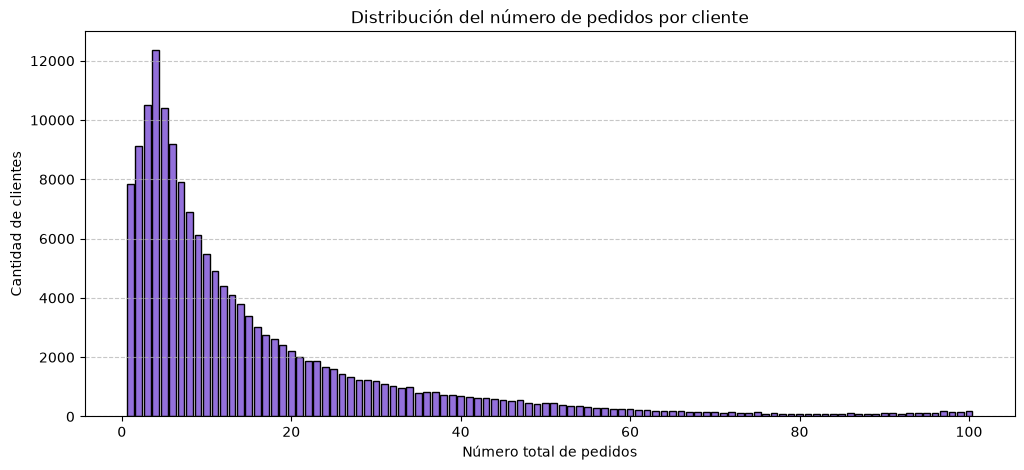

In [42]:
#Graficar la distribución
plt.figure(figsize=(12, 5))
plt.bar(distribucion_pedidos.index, distribucion_pedidos.values, color='mediumpurple', edgecolor='black')
plt.title('Distribución del número de pedidos por cliente')
plt.xlabel('Número total de pedidos')
plt.ylabel('Cantidad de clientes')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

La gran mayoría de los clientes tienen entre 4 y 10 pedidos acumulados. Conforme sube el número de órdenes la cantidad de usuarios va bajando de forma constante aunque se nota un ligero tope al final por el límite de datos registrados en la plataforma.

In [43]:
#1 contamos cuántas veces se pidió cada producto en la tabla de órdenes
top_20_ids = df_order_products['product_id'].value_counts().head(20).reset_index()
top_20_ids.columns = ['product_id', 'total_pedidos']

In [44]:
#2 cruzamos con la tabla de productos para obtener el nombre correspondiente
top_20_productos = top_20_ids.merge(df_products[['product_id', 'product_name']], on='product_id', how='left')

In [45]:
#3 mostramos la tabla resultante con ID y Nombre
top_20_productos[['product_id', 'product_name']]

,product_id,product_name
0,24852,Banana
1,13176,Bag of Organic Bananas
2,21137,Organic Strawberries
3,21903,Organic Baby Spinach
4,47209,Organic Hass Avocado
5,47766,Organic Avocado
6,47626,Large Lemon
7,16797,Strawberries
8,26209,Limes
9,27845,Organic Whole Milk


La lista está casi que dominada por productos frescos, principalmente frutos orgánicos como plátanos, aguacates, fresas y limones. Se demuestra que los artículos de consumo diario y de vida útil corta son los que generan mayor frecuencia de recompra en la plataforma.

In [46]:
#Aquí va agrupar por order_id y contar cuántos productos tiene cada pedido
articulos_por_pedido = df_order_products.groupby('order_id')['product_id'].count()

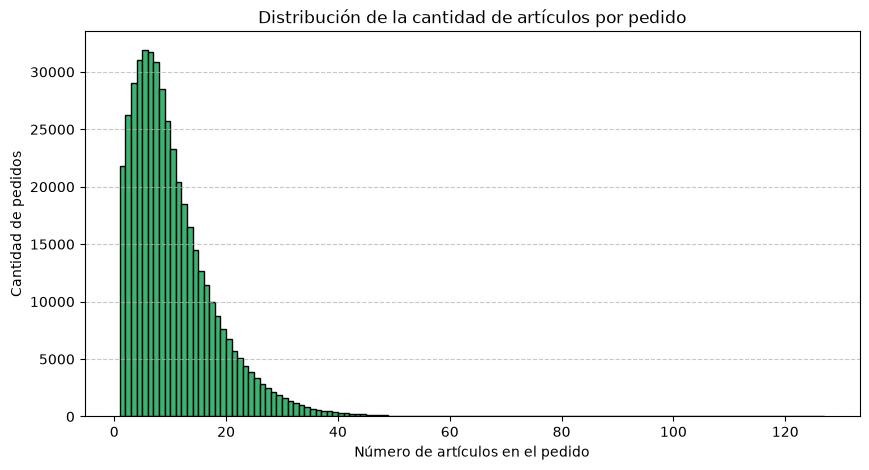

In [47]:
#aquí generamos la gráfica de distribución con un histograma
plt.figure(figsize=(10, 5))
plt.hist(articulos_por_pedido, bins=range(1, articulos_por_pedido.max() + 1), color='mediumseagreen', edgecolor='black')
plt.title('Distribución de la cantidad de artículos por pedido')
plt.xlabel('Número de artículos en el pedido')
plt.ylabel('Cantidad de pedidos')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [48]:
#imprimir métricas importantes: sacar el promedio general y mediana para la conclusión
print(f"Promedio de artículos por pedido: {articulos_por_pedido.mean():.2f}")
print(f"Mediana de artículos por pedido: {articulos_por_pedido.median():.2f}")

Promedio de artículos por pedido: 10.10
Mediana de artículos por pedido: 8.00


El pedido típico contiene 8 artículos (mediana), lo que indica que la mitad de los pedidos incluye 8 o menos productos. El pico de mayor frecuencia (moda) se ubica alrededor de 5-6 artículos. El promedio de 10.10 artículos está inflado por pedidos voluminosos en la cola derecha de la distribución.

In [49]:
# filtramos solo compras repetidas (osea reordered ==1) y contamos los veinte ids más frecuentes.
reordenados_top20 = df_order_products[df_order_products['reordered'] == 1]['product_id'].value_counts().head(20).reset_index()
reordenados_top20.columns = ['product_id', 'total_reordenes']

In [50]:
# hacemos un merge con la tabla de productos para obtener sus nombres
top_20_reordenados = reordenados_top20.merge(df_products[['product_id', 'product_name']], on='product_id', how='left')

In [51]:
# mostramos los resultados limpios organizados por columnas en una tabla
top_20_reordenados[['product_id', 'product_name', 'total_reordenes']]

,product_id,product_name,total_reordenes
0,24852,Banana,55763
1,13176,Bag of Organic Bananas,44450
2,21137,Organic Strawberries,28639
3,21903,Organic Baby Spinach,26233
4,47209,Organic Hass Avocado,23629
5,47766,Organic Avocado,18743
6,27845,Organic Whole Milk,16251
7,47626,Large Lemon,15044
8,27966,Organic Raspberries,14748
9,16797,Strawberries,13945


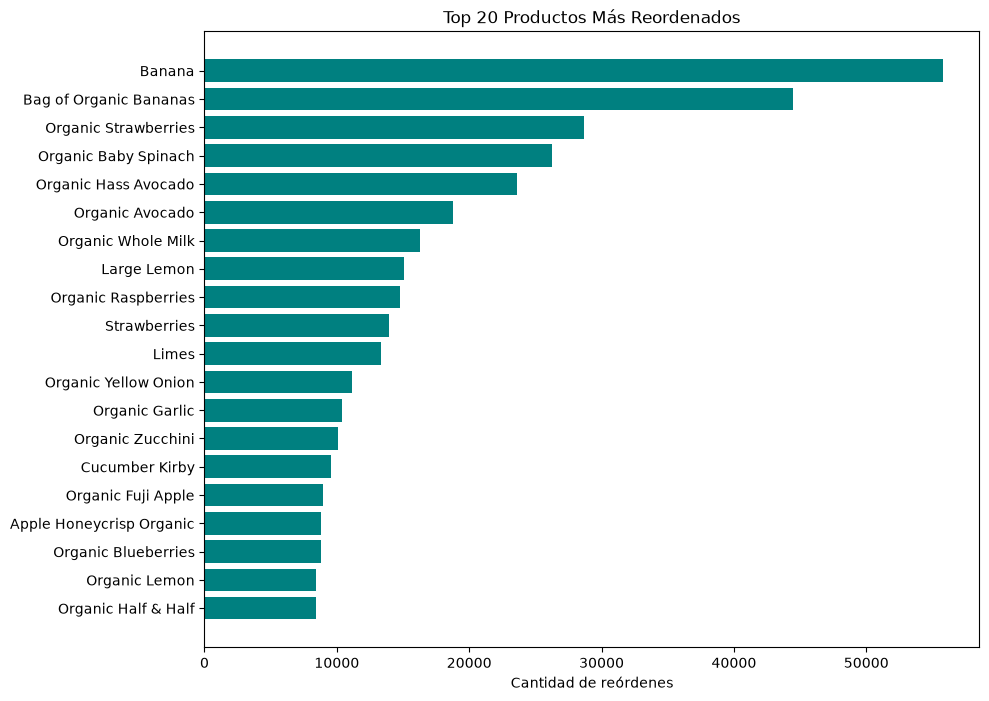

In [52]:
# gráfica del top 20 para mostrar bien la diferencia
plt.figure(figsize=(10, 8))
plt.barh(top_20_reordenados['product_name'].head(20)[::-1], top_20_reordenados['total_reordenes'].head(20)[::-1], color='teal')
plt.title('Top 20 Productos Más Reordenados')
plt.xlabel('Cantidad de reórdenes')
plt.show()

Básicamente son los mismos productos que los más vendidos en general osea plátanos, aguacates, fresas y leche. Es lógico porque son las cosas básicas de la semana que la gente siempre necesita volver a surtir.

In [53]:
# sacamos el promedio de los reordered y agrupamos
tasa_reorden = df_order_products.groupby('product_id')['reordered'].mean().reset_index()
tasa_reorden.columns = ['product_id', 'tasa_recompra']

In [54]:
# le pegamos los nombres de los productos y ordenamos de mayor a menor
tasa_reorden = tasa_reorden.merge(df_products[['product_id', 'product_name']], on='product_id', how='left')
tasa_reorden_ordenada = tasa_reorden.sort_values(by='tasa_recompra', ascending=False)

# ahora se muestran los productos con mayor tasa de recompra
tasa_reorden_ordenada[['product_id', 'product_name', 'tasa_recompra']].head(10)

,product_id,product_name,tasa_recompra
28108,30644,Organic French Roast,1.0
7340,8054,Bissli Smokey Wheat Snacks,1.0
28114,30650,Mushroom Lover's Veggie Burgers,1.0
41002,44747,Frozen Organic Blackberries,1.0
40998,44743,Real Zero Cola,1.0
32921,35897,Ham Hock,1.0
32861,35834,Bulgarian Organic Yogurt,1.0
2684,2939,Cheddar Crunchin' Crackers,1.0
20357,22209,Temples Earl Gray Strong Tea,1.0
20361,22213,2% Reduced Fat Chocolate Milk,1.0


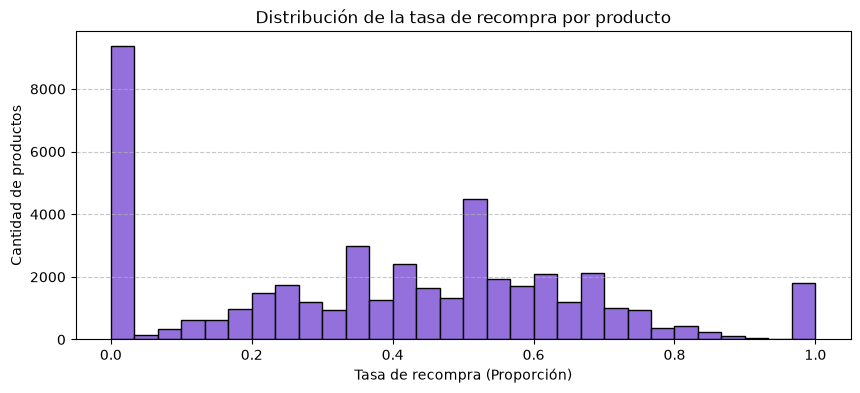

In [55]:
#toca hacer la chula gráfica (histograma) de cómo se distribuyen las tasas de recompra
plt.figure(figsize=(10, 4))
plt.hist(tasa_reorden_ordenada['tasa_recompra'], bins=30, color='mediumpurple', edgecolor='black')
plt.title('Distribución de la tasa de recompra por producto')
plt.xlabel('Tasa de recompra (Proporción)')
plt.ylabel('Cantidad de productos')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

La distribución muestra diferencias importantes en la tasa de recompra entre productos. Algunos artículos de consumo frecuente, como leche, frutas y café, presentan proporciones elevadas de reorden, mientras que otros productos tienen tasas considerablemente menores. Esto refleja que ciertos artículos forman parte de las compras habituales de los usuarios, mientras que otros se adquieren de manera más ocasional.

In [56]:

# se une las tablas para conectar user_id con reordered
df_user_products = df_order_products.merge(df_orders[['order_id', 'user_id']], on='order_id', how='left')

# sacamos el promedio de reordered por cada cliente
tasa_cliente = df_user_products.groupby('user_id')['reordered'].mean().reset_index()
tasa_cliente.columns = ['user_id', 'proporcion_reordenes']

# mostramos los primeros 5 clientes para validar
tasa_cliente.head()


,user_id,proporcion_reordenes
0,2,0.038462
1,4,0.000000
2,5,0.666667
3,6,0.000000
4,7,0.928571


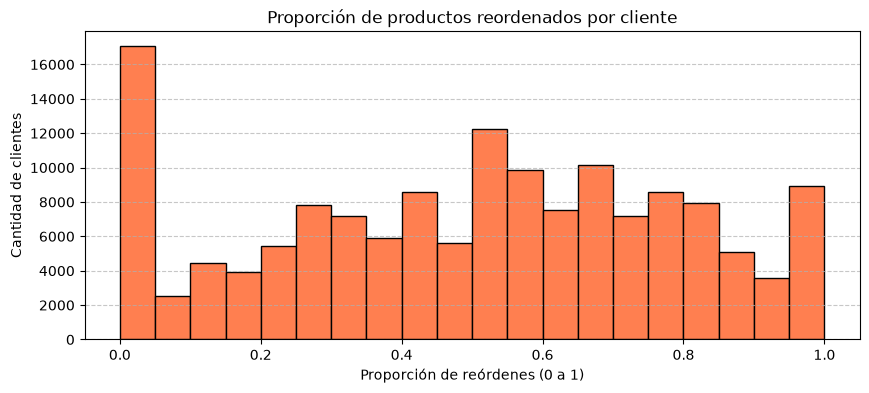

In [57]:
#histograma que nos muestra el comportamiento de los cliente

plt.figure(figsize=(10, 4))
plt.hist(tasa_cliente['proporcion_reordenes'], bins=20, color='coral', edgecolor='black')
plt.title('Proporción de productos reordenados por cliente')
plt.xlabel('Proporción de reórdenes (0 a 1)')
plt.ylabel('Cantidad de clientes')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

La proporción de artículos marcados como reordenados varía entre clientes, lo que refleja diferentes patrones de recurrencia y preferencias de consumo.

In [58]:
#filtramos artículos que fueron agregados a la posición 1
primeros_items = df_order_products[df_order_products['add_to_cart_order'] == 1]['product_id'].value_counts().head(20).reset_index()
primeros_items.columns = ['product_id', 'veces_primero']

In [59]:
#hacemos merge para tener nombres de los productos
top_20_primeros = primeros_items.merge(df_products[['product_id', 'product_name']], on='product_id', how='left')

#tabla limpia con sus columnas
top_20_primeros[['product_id', 'product_name', 'veces_primero']]

,product_id,product_name,veces_primero
0,24852,Banana,15562
1,13176,Bag of Organic Bananas,11026
2,27845,Organic Whole Milk,4363
3,21137,Organic Strawberries,3946
4,47209,Organic Hass Avocado,3390
5,21903,Organic Baby Spinach,3336
6,47766,Organic Avocado,3044
7,19660,Spring Water,2336
8,16797,Strawberries,2308
9,27966,Organic Raspberries,2024


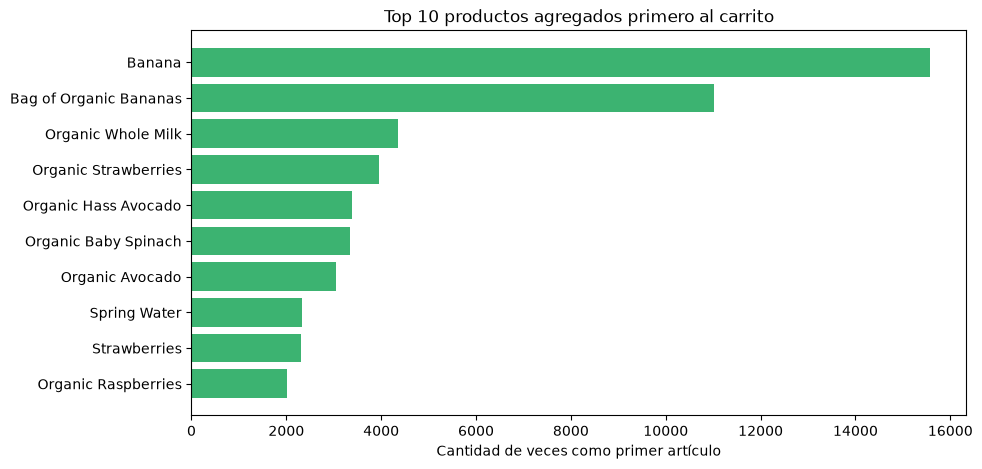

In [60]:
#la gráfica
plt.figure(figsize=(10, 5))
plt.barh(top_20_primeros['product_name'].head(10)[::-1], top_20_primeros['veces_primero'].head(10)[::-1], color='mediumseagreen')
plt.title('Top 10 productos agregados primero al carrito')
plt.xlabel('Cantidad de veces como primer artículo')
plt.show()

Lo primero que la gente mete al carrito al abrir la app son sus básicos esenciales de diario como los plátanos, la leche y aguacates y pues tiene todo el sentido porque entras a la app teniendo en mente exactamente lo indispensable que necesitas surtir y ya después vas agregando el resto de las cosas.

### Conclusion general del proyecto:


En este análisis exploramos a fondo los hábitos de compra de los usuarios para entender qué mueve los pedidos dentro de la plataforma. A lo largo del proyecto se identificaron tres patrones clave:

- El pedido más típico o frecuente contiene entre 5 y 6 artículos (moda). El 50% de los pedidos incluye 8 o menos productos (mediana), mientras que el promedio se sitúa en 10.10 (como promedio matemático) artículos debido al sesgo de compras grandes en la cola derecha
- Los productos con mayor volumen de ventas y más reordenados y que casi siempre se meten primero al carrito son los mismos: plátanos, leches, aguacates y fresas. Demuestra que el usuario entra a la app con la intención directa de surtir su despensa básica antes de explorar otros productos.
- La proporción de artículos reordenados varía entre clientes, lo que refleja diferentes patrones de recurrencia y hábitos de compra. Algunos usuarios muestran una mayor tendencia a repetir productos, mientras que otros incorporan más artículos nuevos en sus pedidos.

Estratégicamente conviene usar los productos de alta recurrencia (como el plátano o la leche) como "gancho" para ofrecer recomendaciones personalizadas o promociones cruzadas justo cuando el cliente abre la app, aprovechando que son los primeros artículos que agrega al carrito.
